In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (f1_score, accuracy_score, precision_score)
from sklearn.metrics import (recall_score, classification_report, confusion_matrix)
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score)

random_state = 42

In [2]:
cv_splits = 5

training_data = pd.read_csv("../dataset/task1_static/train_features.csv")
training_labels = pd.read_csv("../dataset/task1_static/train_labels.csv")
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

validation_data = pd.read_csv("../dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("../dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

In [9]:
selected_features = ["transport", "start_rel", "duration", "server_port", "packet_count_down", "bytes_up", "mean_pkt_size_up", "mean_pkt_size_down", 
                     "std_pkt_size_up", "std_pkt_size_down", "mean_iat", "std_iat", "min_iat", "max_iat", "up_down_packet_ratio", "up_down_byte_ratio"]

low_association_features = ["std_pkt_size_down", "up_down_byte_ratio", "mean_iat",
                            "std_iat", 'min_iat', "max_iat", "server_port"]

deleted_features = [""]

# set(selected_features) - set(low_assoiation_features)
reduced_features = [f for f in selected_features if f not in low_association_features]

skewed_features = ["min_iat", "packet_count_down", "up_down_byte_ratio", "bytes_up", "mean_iat",
                   "duration", "std_iat", "max_iat", "mean_pkt_size_up"]

def add_rate_features(df):
    return df

training_data = add_rate_features(training_data)
validation_data = add_rate_features(validation_data)

X_train = training_data[selected_features].copy()
y_train = training_data["app"].copy()
X_val = validation_data[selected_features].copy()
y_val = validation_data["app"].copy()

def preprocess_data(X, log_features=[]):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()
    log_cols = [c for c in numeric if c in log_features]
    numeric = [c for c in numeric if c not in log_features]
    numeric_pipe = Pipeline([("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("onehot", OneHotEncoder())])
    log_pipe = Pipeline([("log", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())])
    return ColumnTransformer([("numeric", numeric_pipe, numeric),
                              ("categorical", categorical_pipe, categorical),
                              ("log", log_pipe, log_cols)])

def report(search, Xtr, ytr, Xte, yte, experiment_name):
    start = time.time()
    search.fit(Xtr, ytr)
    elapsed = time.time() - start
    best_model = search.best_estimator_
    pred = best_model.predict(Xte)
    print("\n", experiment_name)
    print("Best CV macro-F1:", search.best_score_)
    print("Best parameters:", search.best_params_)
    print("Test macro-F1:", f1_score(yte, pred, average="macro"))
    print("Test accuracy:", accuracy_score(yte, pred))
    print(classification_report(yte, pred, zero_division=0))
    cm = confusion_matrix(yte, pred, labels=best_model.classes_)
    plt.figure(figsize=(10,8))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
                xticklabels=best_model.classes_, yticklabels=best_model.classes_)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion Matrix - {experiment_name}")
    plt.tight_layout(); plt.show()
    results = pd.DataFrame(search.cv_results_)
    results["experiment"] = experiment_name
    results["elapsed_seconds_search"] = elapsed
    results.to_csv(f"{experiment_name.lower().replace(' ', '_')}_all_cv_results.csv", index=False)    
    return search, results, pred

def run_experiment(model, param_grid, model_name, feature_list, log_features=[], tag=None):
    Xtr, Xte = X_train[feature_list].copy(), X_val[feature_list].copy()
    pipe = Pipeline([("preprocess", preprocess_data(Xtr, log_features)), ("model", model)])
    grid = {"model__" + k: v for k, v in param_grid.items()}
    search = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True, return_train_score=True, verbose=1)
    if tag is None:
        tag = "_E1_16features" if len(feature_list)==16 else "_E2_reduced"
    experiment_name = model_name + tag
    return report(search, Xtr, y_train, Xte, y_val, experiment_name)

def evaluate(model, Xte, yte):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)
    return {"Accuracy": accuracy_score(yte, pred),
            "Balanced_Accuracy": balanced_accuracy_score(yte, pred),
            "F1_weighted": f1_score(yte, pred, average="weighted"),
            "Macro_F1": f1_score(yte, pred, average="macro"),
            "AUC_ROC": roc_auc_score(yte, proba, multi_class="ovr")}

In [10]:
len(selected_features)

16

#### Model and tuning space

In [11]:
cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=random_state)
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100], 
    'solver': ['lbfgs'], 
    'class_weight': [None, 'balanced']
}

#### Experiment-1: All 16 selected features

Fitting 5 folds for each of 10 candidates, totalling 50 fits

 logistic_regression_E1_16features
Best CV macro-F1: 0.5613228297051827
Best parameters: {'model__C': 100, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Test macro-F1: 0.6400525525525526
Test accuracy: 0.6867469879518072
              precision    recall  f1-score   support

    facebook       0.00      0.00      0.00         3
      google       0.79      0.58      0.67        33
   instagram       1.00      0.60      0.75         5
     mozilla       0.90      0.90      0.90        10
           x       1.00      0.78      0.88        18
     youtube       0.52      0.86      0.65        14

    accuracy                           0.69        83
   macro avg       0.70      0.62      0.64        83
weighted avg       0.79      0.69      0.72        83



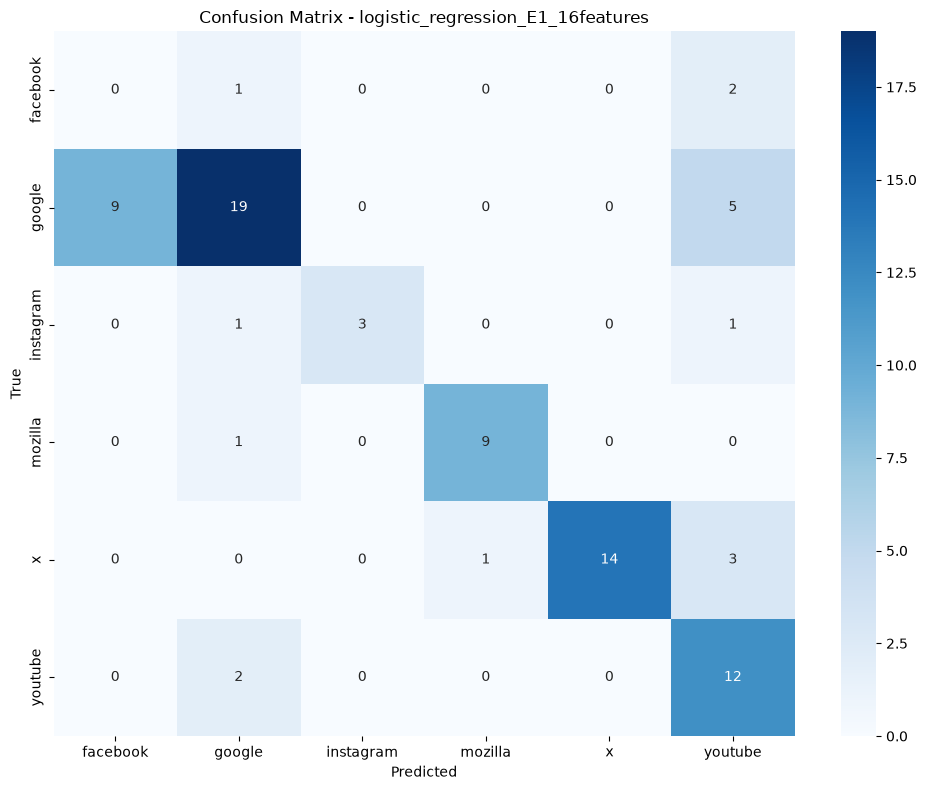

In [12]:
model_e1 = LogisticRegression(max_iter=3000, random_state=random_state)
search_e1, results_e1, pred_e1 = run_experiment(model_e1, param_grid, 'logistic_regression', selected_features)

#### Experiment-2: Reduced feature set (9 features)

Fitting 5 folds for each of 10 candidates, totalling 50 fits

 logistic_regression_E2_reduced
Best CV macro-F1: 0.515479755746742
Best parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Test macro-F1: 0.6091964755250759
Test accuracy: 0.6265060240963856
              precision    recall  f1-score   support

    facebook       0.08      0.33      0.13         3
      google       0.89      0.48      0.63        33
   instagram       1.00      0.80      0.89         5
     mozilla       0.44      0.80      0.57        10
           x       0.94      0.83      0.88        18
     youtube       0.53      0.57      0.55        14

    accuracy                           0.63        83
   macro avg       0.65      0.64      0.61        83
weighted avg       0.76      0.63      0.66        83



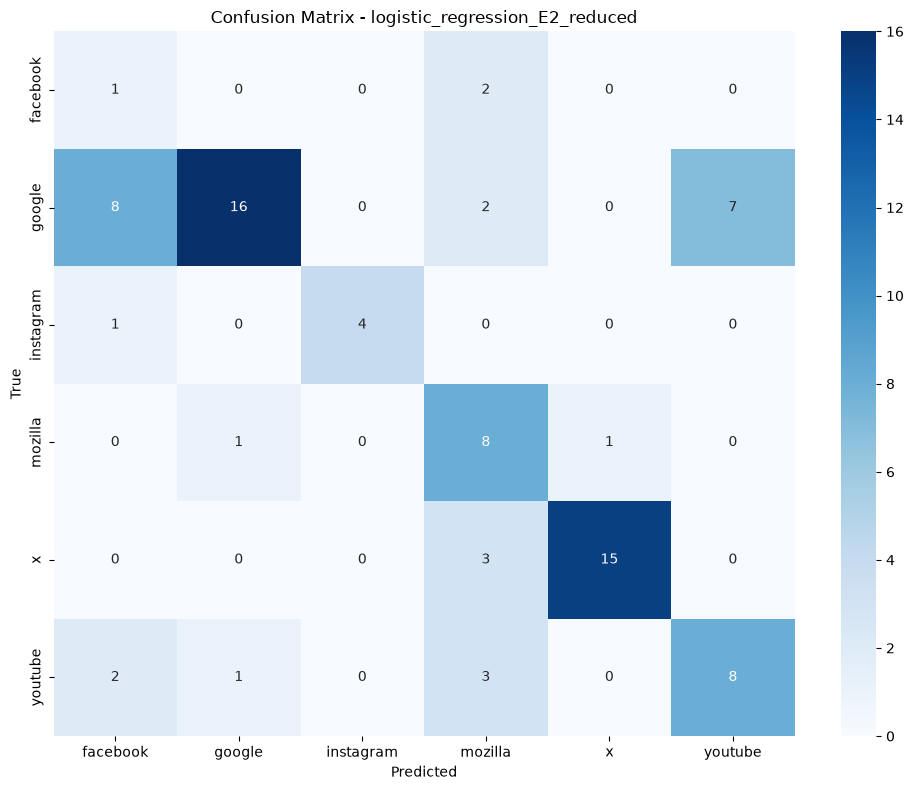

In [13]:
model_e2 = LogisticRegression(max_iter=3000, random_state=random_state)
search_e2, results_e2, pred_e2 = run_experiment(model_e2, param_grid, 'logistic_regression', reduced_features)

#### Experiment-3: Log-transform of the skewed features (16 features)

Fitting 5 folds for each of 10 candidates, totalling 50 fits

 logistic_regression_E3_log
Best CV macro-F1: 0.5858212237274041
Best parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Test macro-F1: 0.6632672882672882
Test accuracy: 0.6867469879518072
              precision    recall  f1-score   support

    facebook       0.10      0.33      0.15         3
      google       0.86      0.55      0.67        33
   instagram       0.83      1.00      0.91         5
     mozilla       0.64      0.90      0.75        10
           x       1.00      0.78      0.88        18
     youtube       0.56      0.71      0.62        14

    accuracy                           0.69        83
   macro avg       0.66      0.71      0.66        83
weighted avg       0.78      0.69      0.71        83



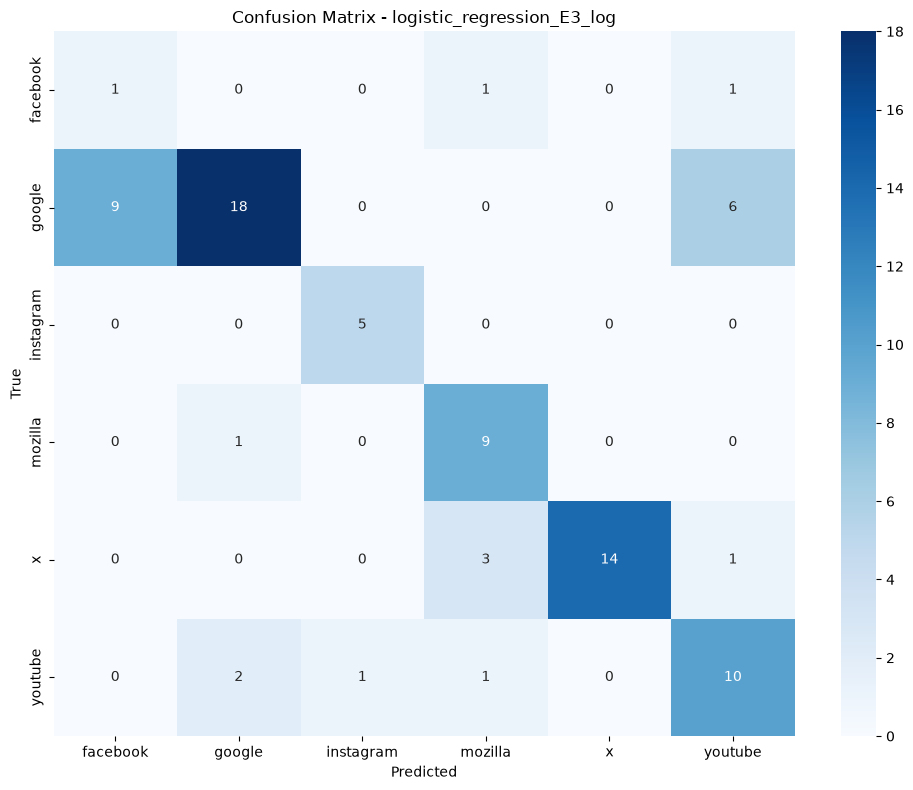

In [14]:
model_e3 = LogisticRegression(max_iter=3000, random_state=random_state)
search_e3, results_e3, pred_e3 = run_experiment(model_e3, param_grid, 'logistic_regression', selected_features,
                                                log_features=skewed_features, tag='_E3_log')

### Experiment-4: Feature Engineering

In [15]:
print("selected_features:\n", selected_features)
print("\nremoved_features:\n", )

selected_features:
 ['transport', 'start_rel', 'duration', 'server_port', 'packet_count_down', 'bytes_up', 'mean_pkt_size_up', 'mean_pkt_size_down', 'std_pkt_size_up', 'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'up_down_packet_ratio', 'up_down_byte_ratio']

removed_features:



#### Compare feature configurations

In [16]:
experiments = {"E1_16feat": (search_e1, selected_features),
               "E2_reduced_feat": (search_e2, reduced_features),
               "E3_log": (search_e3, selected_features)}

comparision = []
for name, (search, feats) in experiments.items():
    row = {"Experiment": name, "Best_CV_MacroF1": search.best_score_}
    row.update(evaluate(search.best_estimator_, X_val[feats], y_val))
    comparision.append(row)
comparision = pd.DataFrame(comparision)
display(comparision.round(4))
comparision.to_csv('feature_ablation_comparison_logistic_regression.csv', index=False)

,Experiment,Best_CV_MacroF1,Accuracy,Balanced_Accuracy,F1_weighted,Macro_F1,AUC_ROC
0,E1_16feat,0.5613,0.6867,0.6184,0.7178,0.6401,0.8209
1,E2_reduced_feat,0.5155,0.6265,0.6372,0.6611,0.6092,0.9070
2,E3_log,0.5858,0.6867,0.7118,0.7109,0.6633,0.8570


### Class imbalance: weighted loss vs threshold tuning

Fitting 5 folds for each of 5 candidates, totalling 25 fits

 logistic_regression_baseline_unweighted
Best CV macro-F1: 0.5551311301203775
Best parameters: {'model__C': 1, 'model__class_weight': None, 'model__solver': 'lbfgs'}
Test macro-F1: 0.5719977734683618
Test accuracy: 0.7349397590361446
              precision    recall  f1-score   support

    facebook       0.00      0.00      0.00         3
      google       0.69      0.94      0.79        33
   instagram       1.00      0.40      0.57         5
     mozilla       0.60      0.60      0.60        10
           x       0.94      0.83      0.88        18
     youtube       0.70      0.50      0.58        14

    accuracy                           0.73        83
   macro avg       0.65      0.55      0.57        83
weighted avg       0.73      0.73      0.71        83



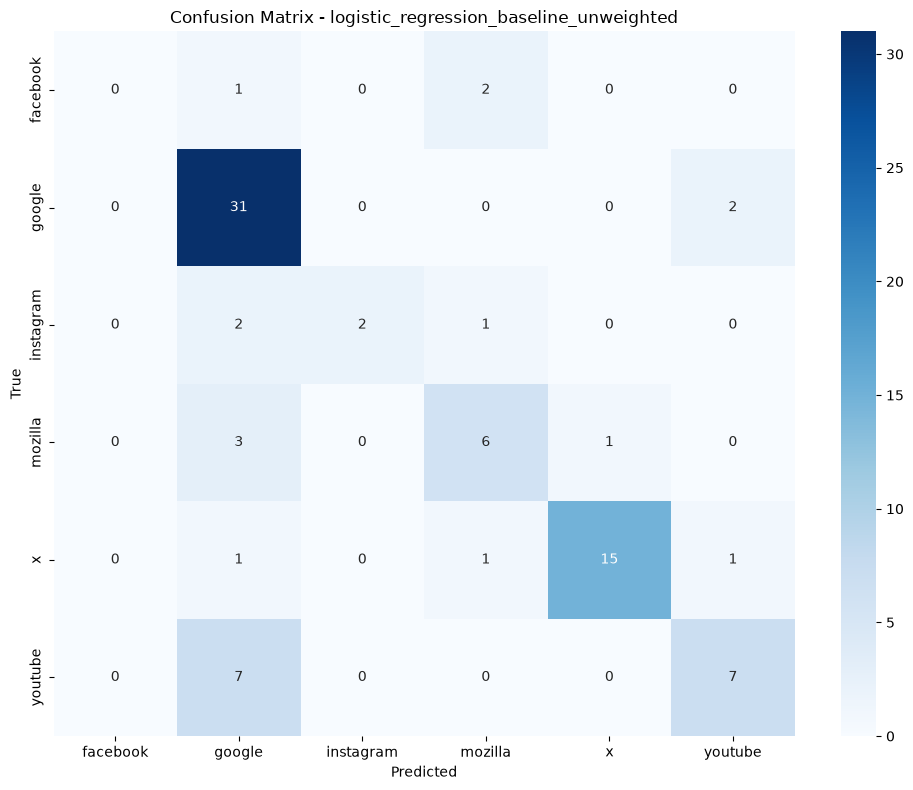

Fitting 5 folds for each of 5 candidates, totalling 25 fits

 logistic_regression_weighted_loss
Best CV macro-F1: 0.5613228297051827
Best parameters: {'model__C': 100, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Test macro-F1: 0.6400525525525526
Test accuracy: 0.6867469879518072
              precision    recall  f1-score   support

    facebook       0.00      0.00      0.00         3
      google       0.79      0.58      0.67        33
   instagram       1.00      0.60      0.75         5
     mozilla       0.90      0.90      0.90        10
           x       1.00      0.78      0.88        18
     youtube       0.52      0.86      0.65        14

    accuracy                           0.69        83
   macro avg       0.70      0.62      0.64        83
weighted avg       0.79      0.69      0.72        83



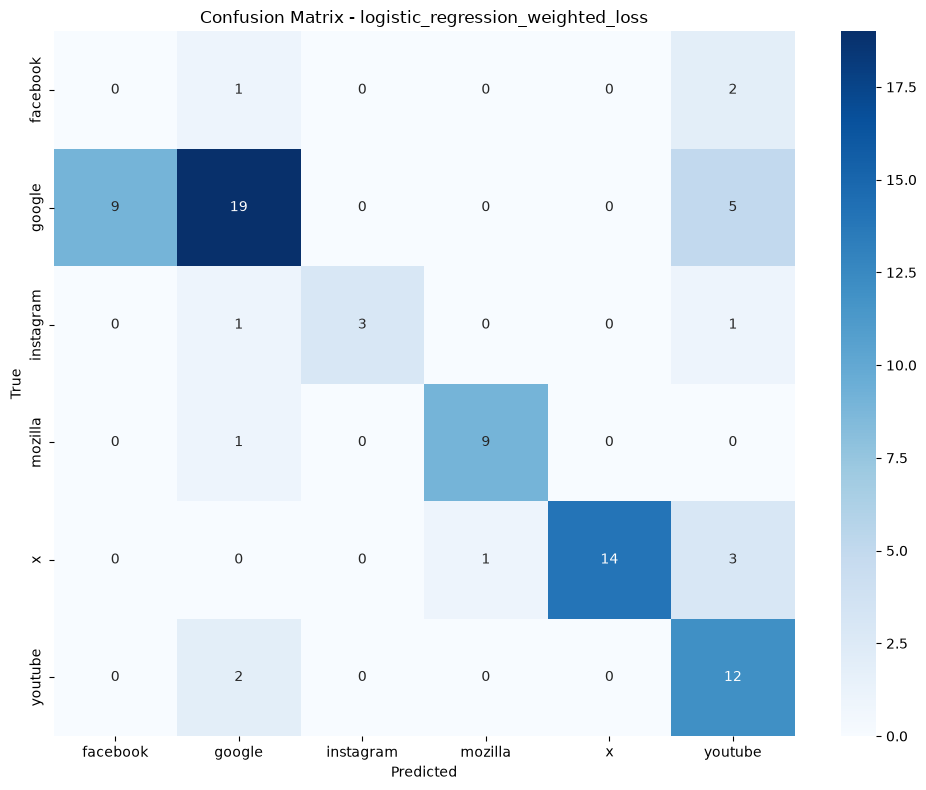

In [17]:
grid_unweighted = dict(param_grid, class_weight=[None])
grid_weighted = dict(param_grid, class_weight=['balanced'])

search_base, _, pred_base = run_experiment(LogisticRegression(max_iter=3000, random_state=random_state), grid_unweighted,
                                           'logistic_regression', selected_features, tag='_baseline_unweighted')
search_w, _, pred_w = run_experiment(LogisticRegression(max_iter=3000, random_state=random_state), grid_weighted,
                                     'logistic_regression', selected_features, tag='_weighted_loss')

In [18]:
base_model = search_base.best_estimator_
classes = base_model.classes_
oof_proba = cross_val_predict(base_model, X_train[selected_features], y_train, cv=cv, method='predict_proba')
y_train_idx = np.searchsorted(classes, y_train)

weights = np.ones(len(classes))
candidates = np.round(np.arange(0.2, 5.01, 0.1), 2)
best_oof = f1_score(y_train_idx, oof_proba.argmax(axis=1), average='macro')
print("OOF macro-F1 before:", best_oof)
for _ in range(3):
    for k in range(len(classes)):
        for w in candidates:
            trial = weights.copy()
            trial[k] = w
            score = f1_score(y_train_idx, (oof_proba * trial).argmax(axis=1), average='macro')
            if score > best_oof + 1e-9:
                best_oof, weights = score, trial
print("OOF macro-F1 after: ", best_oof)
print("class multipliers:", dict(zip(classes, weights)))

val_proba = base_model.predict_proba(X_val[selected_features])
pred_thr = classes[(val_proba * weights).argmax(axis=1)]
print(classification_report(y_val, pred_thr, zero_division=0))

OOF macro-F1 before: 0.5692322692095648
OOF macro-F1 after:  0.5910052317687786
class multipliers: {'facebook': np.float64(0.3), 'google': np.float64(0.9), 'instagram': np.float64(1.0), 'mozilla': np.float64(2.7), 'x': np.float64(1.2), 'youtube': np.float64(1.0)}
              precision    recall  f1-score   support

    facebook       0.00      0.00      0.00         3
      google       0.82      0.94      0.87        33
   instagram       1.00      0.40      0.57         5
     mozilla       0.45      0.90      0.60        10
           x       1.00      0.67      0.80        18
     youtube       0.73      0.57      0.64        14

    accuracy                           0.75        83
   macro avg       0.67      0.58      0.58        83
weighted avg       0.78      0.75      0.74        83



In [19]:
imbalance = pd.DataFrame([
    {"Setting": name,
     "Balanced_Accuracy": balanced_accuracy_score(y_val, pred),
     "F1_weighted": f1_score(y_val, pred, average='weighted'),
     "Macro_F1": f1_score(y_val, pred, average='macro')}
    for name, pred in [("Baseline", pred_base), ("Weighted Loss", pred_w), ("Optimal Threshold", pred_thr)]
])
display(imbalance.round(4))
imbalance.to_csv('class_imbalance_comparison.csv', index=False)

,Setting,Balanced_Accuracy,F1_weighted,Macro_F1
0,Baseline,0.5455,0.7125,0.5720
1,Weighted Loss,0.6184,0.7178,0.6401
2,Optimal Threshold,0.5796,0.7353,0.5808


In [20]:
coefficients = search_e1.best_estimator_.named_steps['model'].coef_[0]
print(coefficients)

[  1.0461691   -0.52612191   0.          -6.88673678  -0.47608176
   0.4451219   -1.34944214  -0.80115416  -0.06962829  12.82064213
 -21.23607724  -0.03329809   7.2945023   -1.42126565  -0.03326513
  -3.27342162   2.76755895]


In [21]:
pipeline = search_e1.best_estimator_

feature_names = pipeline.named_steps['preprocess'].get_feature_names_out()
coefficients = pipeline.named_steps['model'].coef_[0]

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'abs_coefficient': np.abs(coefficients)
}).sort_values('abs_coefficient', ascending=False)

coef_df

,feature,coefficient,abs_coefficient
10,numeric__std_iat,-21.236077,21.236077
9,numeric__mean_iat,12.820642,12.820642
12,numeric__max_iat,7.294502,7.294502
3,numeric__packet_count_down,-6.886737,6.886737
15,categorical__transport_tcp,-3.273422,3.273422
16,categorical__transport_udp,2.767559,2.767559
13,numeric__up_down_packet_ratio,-1.421266,1.421266
6,numeric__mean_pkt_size_down,-1.349442,1.349442
0,numeric__start_rel,1.046169,1.046169
7,numeric__std_pkt_size_up,-0.801154,0.801154
